# PhageLysData EDA manuscript panel

This notebook builds the consolidated EDA figure directly from the frozen outputs under `EDA_results/E0`–`E6`.

Current layout and story:

- **A** percentage-based horizontal bars for dataset composition;
- **B** sequence-length distributions for primary groups and core subtypes;
- **C** amino-acid composition effects across target/background contrasts;
- **D** top non-length physicochemical descriptor effects;
- **E** selected physicochemical-property distributions, emphasizing interpretable properties;
- **F** ESM2-T30 t-SNE views only, with legends below each scatter plot;
- **G** background robustness plus subtype-neighborhood consistency, with the shared legend moved below the robustness curves.

The notebook does not use hard-coded machine-specific paths. It discovers the project root from the current working directory and then reads the expected files from the existing `EDA_results` hierarchy.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
sns.set_theme(
    context="paper",
    style="white",
    font="DejaVu Sans",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#7F93A8",
        "xtick.color": "#3F5061",
        "ytick.color": "#3F5061",
        "axes.labelcolor": "#31465A",
        "text.color": "#31465A",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

mpl.rcParams.update({
    "font.size": 9.5,
    "axes.labelsize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
})

COLORS = {
    "P_core": "#4F81BD",
    "P core": "#4F81BD",
    "N_easy": "#9BB7D3",
    "N_hard": "#5FA8A0",
    "Unknown": "#B8B8D6",
    "Negative": "#8EABC8",
    "Endolysin": "#4F81BD",
    "DPO": "#7E9FC7",
    "VAL": "#65B5A6",
    "E2 composition": "#8FB1D5",
    "E3 physicochemical": "#72B7B2",
    "E2+E3 combined": "#507FB4",
    "ESM2-T6": "#A89CC8",
    "ESM2-T30": "#6F5FA8",
}

DIVERGING_CMAP = sns.diverging_palette(245, 15, s=70, l=65, center="light", as_cmap=True)
LETTER_COLOR = "#315A84"

DISPLAY_NAMES = {
    "P_core": "P core",
    "N_easy": "N easy",
    "N_hard": "N hard",
    "N_mixed": "N mixed",
    "Unknown": "Unknown",
    "Negative": "Negative",
}

# ------------------------------------------------------------------
# Project-root and frozen-output discovery
# ------------------------------------------------------------------
def discover_project_root() -> Path:
    cwd = Path.cwd().resolve()

    # Preserve the layout used by the original EDA notebook when run
    # from a directory named EDA.
    preferred = cwd.parent if cwd.name.lower() == "eda" else cwd

    candidates = []
    for p in [preferred, cwd, *cwd.parents]:
        if p not in candidates:
            candidates.append(p)

    for root in candidates:
        if (root / "EDA_results").is_dir():
            return root

    raise FileNotFoundError(
        "Could not locate the PhageLysData project root. Run this notebook "
        "from the project directory (or a subdirectory) containing EDA_results/."
    )

PROJECT_ROOT = discover_project_root()
EDA_ROOT = PROJECT_ROOT / "EDA_results"
OUTPUT_DIR = EDA_ROOT / "E_panel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILE_LOCATIONS = {
    "phagelytic_eda_universe.csv": "E0",
    "dataset_composition.tsv": "E1",
    "length_summary.tsv": "E1",
    "aac_effects_global.tsv": "E2",
    "global_descriptor_effects.tsv": "E3",
    "descriptor_rankings.tsv": "E3",
    "descriptor_statistics.tsv": "E3",
    "physicochemical_descriptors.parquet": "E3",
    "embedding_esm2_t30_tsne_global.tsv": "E5_v2",
    "embedding_esm2_t30_tsne_subtypes.tsv": "E5_v2",
    "background_sensitivity.tsv": "E6",
    "subtype_consistency.tsv": "E6",
}

def find_file(filename: str) -> Path:
    if filename in FILE_LOCATIONS:
        expected = EDA_ROOT / FILE_LOCATIONS[filename] / filename
        if expected.is_file():
            return expected

    # Safe fallback inside the already identified EDA tree only.
    matches = list(EDA_ROOT.rglob(filename))
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise FileNotFoundError(
            f"Multiple copies of {filename!r} found under {EDA_ROOT}; "
            "please keep the frozen EDA output hierarchy unambiguous."
        )
    raise FileNotFoundError(f"Could not locate required frozen output: {filename}")

print("Project root:", PROJECT_ROOT)
print("EDA root    :", EDA_ROOT)
print("Output dir  :", OUTPUT_DIR)


Project root: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
EDA root    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results
Output dir  : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel


In [2]:
# ------------------------------------------------------------------
# Load the frozen E0–E6 outputs used by the figure
# ------------------------------------------------------------------
dataset_composition = pd.read_csv(find_file("dataset_composition.tsv"), sep="\t")

# E0 is used only for group membership and sequence IDs.
eda_universe = pd.read_csv(
    find_file("phagelytic_eda_universe.csv"),
    usecols=["sequence_uid", "sequence_length", "phage_lytic", "clean_subtype", "P_core", "N_easy", "N_hard"],
)

aac_effects_global = pd.read_csv(find_file("aac_effects_global.tsv"), sep="\t")
global_descriptor_effects = pd.read_csv(find_file("global_descriptor_effects.tsv"), sep="\t")
descriptor_rankings = pd.read_csv(find_file("descriptor_rankings.tsv"), sep="\t")
descriptor_statistics = pd.read_csv(find_file("descriptor_statistics.tsv"), sep="\t")

t30_tsne_global = pd.read_csv(find_file("embedding_esm2_t30_tsne_global.tsv"), sep="\t")
t30_tsne_subtypes = pd.read_csv(find_file("embedding_esm2_t30_tsne_subtypes.tsv"), sep="\t")

background_sensitivity = pd.read_csv(find_file("background_sensitivity.tsv"), sep="\t")
subtype_consistency = pd.read_csv(find_file("subtype_consistency.tsv"), sep="\t")

print("Loaded frozen E0, E1, E2, E3, E5_v2 and E6 outputs.")


Loaded frozen E0, E1, E2, E3, E5_v2 and E6 outputs.


In [3]:
# ------------------------------------------------------------------
# Prepare panel data
# ------------------------------------------------------------------

# ================================================================
# A — percentage composition
# ================================================================
primary_comp = (
    dataset_composition
    .query("section == 'phage_lytic'")
    .set_index("label")
    .loc[["yes", "no", "unknown"]]
    .reset_index()
)
primary_comp["display"] = ["P core", "Negative", "Unknown"]
primary_comp["percent"] = primary_comp["fraction"] * 100

core_subtypes = dataset_composition.query("section == 'core_subtype'").copy()
subtype_comp = pd.DataFrame({
    "display": ["Endolysin", "DPO", "VAL"],
    "count": [
        int(core_subtypes.loc[core_subtypes["label"].eq("endolysin"), "count"].iloc[0]),
        int(core_subtypes.loc[core_subtypes["label"].eq("depolymerase"), "count"].iloc[0]),
        int(core_subtypes.loc[core_subtypes["label"].eq("virion_associated_lytic_enzyme"), "count"].iloc[0]),
    ],
})
subtype_comp["percent"] = subtype_comp["count"] / subtype_comp["count"].sum() * 100

# ================================================================
# B — full length distributions
# ================================================================
length_global = eda_universe.loc[:, ["sequence_length", "phage_lytic", "P_core", "N_easy", "N_hard"]].copy()
length_global["group"] = np.select(
    [
        length_global["P_core"].eq(True),
        length_global["N_easy"].eq(True),
        length_global["N_hard"].eq(True),
        length_global["phage_lytic"].eq("unknown"),
    ],
    ["P_core", "N_easy", "N_hard", "Unknown"],
    default="Other",
)
length_global = length_global.loc[
    length_global["group"].isin(["P_core", "N_easy", "N_hard", "Unknown"]),
    ["sequence_length", "group"],
].copy()

length_subtypes = eda_universe.loc[
    eda_universe["clean_subtype"].isin([
        "endolysin",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ]),
    ["sequence_length", "clean_subtype"],
].copy()
length_subtypes["group"] = length_subtypes["clean_subtype"].map({
    "endolysin": "Endolysin",
    "depolymerase": "DPO",
    "virion_associated_lytic_enzyme": "VAL",
})

# ================================================================
# C — all 20 amino-acid composition effects
# ================================================================
AAC_ORDER = list("ACDEFGHIKLMNPQRSTVWY")
contrast_map = {
    "P_core_vs_N_easy": "P core vs N easy",
    "P_core_vs_N_hard": "P core vs N hard",
    "P_core_vs_N_mixed": "P core vs N mixed",
}
contrast_order = ["P core vs N easy", "P core vs N hard", "P core vs N mixed"]

aac_df = aac_effects_global.loc[
    aac_effects_global["feature"].str.startswith("aac_freq_")
    & aac_effects_global["contrast"].isin(contrast_map)
].copy()
aac_df["aa"] = aac_df["feature"].str.replace("aac_freq_", "", regex=False)
aac_df["contrast_short"] = aac_df["contrast"].map(contrast_map)
aac_matrix = (
    aac_df
    .pivot(index="contrast_short", columns="aa", values="cliffs_delta")
    .reindex(index=contrast_order, columns=AAC_ORDER)
)

# ================================================================
# D — top non-length physicochemical descriptors
# ================================================================
ranked_desc = (
    descriptor_rankings
    .query("scope == 'global_target_vs_background' and primary_ranking_eligible == True")
    .sort_values("rank_primary_non_length_proxy")
)
top_features = ranked_desc["feature"].dropna().head(8).tolist()

def short_descriptor(name):
    lookup = {
        "structural_propensity_helix_mean": "helix",
        "global_basic_hydropathy_std": "hydropathy SD",
        "order_disorder_flexibility_fraction": "flexibility",
        "aaindex_FAUJ880104_mean": "AAindex FAUJ",
        "global_basic_charged_fraction": "charged frac.",
        "global_basic_fcr": "FCR",
        "global_basic_polarity_mean": "polarity",
        "global_basic_polarity_std": "polarity SD",
    }
    return lookup.get(name, name.replace("global_basic_", "").replace("_", " "))

desc_df = global_descriptor_effects.loc[
    global_descriptor_effects["contrast"].isin(contrast_map)
    & global_descriptor_effects["feature"].isin(top_features)
].copy()
desc_df["contrast_short"] = desc_df["contrast"].map(contrast_map)
desc_df["feature_short"] = desc_df["feature"].map(short_descriptor)
desc_order = [short_descriptor(x) for x in top_features]
desc_matrix = (
    desc_df
    .pivot(index="contrast_short", columns="feature_short", values="cliffs_delta")
    .reindex(index=contrast_order, columns=desc_order)
)

# ================================================================
# E — selected high-priority descriptor distributions
# ================================================================
# These three are deliberately selected from the ranked descriptors in D:
# one structural, one hydropathy-related, and one charge/composition-related.
preferred_properties = [
    "structural_propensity_helix_mean",
    "order_disorder_flexibility_fraction",
    "global_basic_charged_fraction",
]
selected_properties = [f for f in preferred_properties if f in top_features]
if len(selected_properties) < 3:
    selected_properties += [f for f in top_features if f not in selected_properties][:3-len(selected_properties)]

PROPERTY_LABELS = {
    "structural_propensity_helix_mean": "Helix propensity",
    "global_basic_hydropathy_std": "Hydropathy SD",
    "global_basic_charged_fraction": "Charged fraction",
    "order_disorder_flexibility_fraction": "Flexibility fraction",
    "aaindex_FAUJ880104_mean": "AAIndex FAUJ880104",
    "global_basic_fcr": "FCR",
    "global_basic_polarity_mean": "Mean polarity",
    "global_basic_polarity_std": "Polarity SD",
}

property_mode = "summary"
property_raw = None
parquet_path = find_file("physicochemical_descriptors.parquet")

# Use the original E3 descriptor values whenever a parquet backend is available.
# If the local environment lacks one, the notebook falls back to the frozen E3
# quantile summaries rather than failing.
try:
    property_raw = pd.read_parquet(
        parquet_path,
        columns=["sequence_uid", *selected_properties],
    )
    property_mode = "raw"
except Exception:
    try:
        import polars as pl
        pl_df = pl.read_parquet(
            parquet_path,
            columns=["sequence_uid", *selected_properties],
        )
        property_raw = pd.DataFrame(pl_df.to_dict(as_series=False))
        property_mode = "raw"
    except Exception:
        property_mode = "summary"

if property_mode == "raw":
    membership = eda_universe[["sequence_uid", "P_core", "N_easy", "N_hard"]].copy()
    property_raw = property_raw.merge(membership, on="sequence_uid", how="inner")
    raw_groups = []
    for group in ["P_core", "N_easy", "N_hard"]:
        temp = property_raw.loc[property_raw[group].astype(bool), ["sequence_uid", *selected_properties]].copy()
        temp["group"] = group
        raw_groups.append(temp)
    property_raw = pd.concat(raw_groups, ignore_index=True)
else:
    property_summary = descriptor_statistics.loc[
        descriptor_statistics["section"].eq("primary_state")
        & descriptor_statistics["group"].isin(["P_core", "N_easy", "N_hard"])
        & descriptor_statistics["feature"].isin(selected_properties)
    ].copy()

print("Panel E descriptor mode:", property_mode)
print("Selected properties:", [PROPERTY_LABELS.get(x, x) for x in selected_properties])

# ================================================================
# F — ESM2-T30 t-SNE only
# ================================================================
e5_global = t30_tsne_global.loc[
    t30_tsne_global["sequence_state"].isin(["P_core", "N_easy", "N_hard"])
].copy()
e5_subtypes = t30_tsne_subtypes.loc[
    t30_tsne_subtypes["subtype_label"].isin([
        "endolysin",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ])
].copy()

# ================================================================
# G — representation robustness and subtype consistency
# ================================================================
rep_order = [
    "E2 composition",
    "E3 physicochemical",
    "E2+E3 combined",
    "ESM2-T6",
    "ESM2-T30",
]

bg_sil = background_sensitivity.loc[
    background_sensitivity["metric"].eq("silhouette")
    & background_sensitivity["group"].isna()
    & background_sensitivity["display_name"].isin(rep_order)
].copy()

subtype_knn = subtype_consistency.loc[
    subtype_consistency["metric"].eq("same_subtype_knn_fraction")
    & subtype_consistency["display_name"].isin(rep_order)
].copy()
subtype_knn_rep = (
    subtype_knn
    .groupby("display_name", as_index=False)["value"]
    .mean()
    .set_index("display_name")
    .reindex(rep_order)
    .reset_index()
)

HEATMAP_LIM = max(
    float(np.nanmax(np.abs(aac_matrix.to_numpy()))),
    float(np.nanmax(np.abs(desc_matrix.to_numpy()))),
)

print("Prepared all panels.")


Panel E descriptor mode: raw
Selected properties: ['Helix propensity', 'Flexibility fraction', 'Charged fraction']
Prepared all panels.


In [4]:
# ------------------------------------------------------------------
# Plot helpers
# ------------------------------------------------------------------
def add_panel_letter(ax, letter, x=-0.08, y=1.04):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=18,
        fontweight="bold",
        color=LETTER_COLOR,
        zorder=30,
    )


def style_axis(ax, grid=False, axis="y"):
    if grid:
        ax.grid(True, axis=axis, color="#DCE7F0", linewidth=0.75, alpha=0.8)
    else:
        ax.grid(False)
    sns.despine(ax=ax)


def plot_percentage_bars(ax, table, order, title):
    work = table.set_index("display").loc[order].reset_index()
    y = np.arange(len(work))[::-1]
    colors = [COLORS[g] for g in work["display"]]
    ax.barh(y, work["percent"], color=colors, height=0.62, edgecolor="white", linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([DISPLAY_NAMES.get(x, x) for x in work["display"]], fontsize=8.6)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Composition (%)")
    ax.set_title(title, fontsize=9.8, loc="left", pad=2, fontweight="bold")
    for yy, pct, count in zip(y, work["percent"], work["count"]):
        x = min(pct + 2.0, 98.0)
        ha = "left" if pct < 92 else "right"
        if pct >= 92:
            x = pct - 1.5
        ax.text(x, yy, f"{pct:.1f}%", va="center", ha=ha, fontsize=8.3, fontweight="bold", color="#31465A")
    style_axis(ax, grid=True, axis="x")


def plot_length_distribution(ax, df, order, palette):
    work = df.loc[df["sequence_length"].gt(0) & df["group"].isin(order)].copy()
    work["log10_length"] = np.log10(work["sequence_length"].astype(float))

    lo = np.log10(max(5, work["sequence_length"].quantile(0.001)))
    hi = np.log10(work["sequence_length"].quantile(0.997))
    bins = np.linspace(lo, hi, 34)

    for group in order:
        sub = work.loc[work["group"].eq(group)]
        vals = sub["log10_length"]
        ax.hist(
            vals, bins=bins, density=True, histtype="stepfilled",
            color=palette[group], alpha=0.055, edgecolor="none",
        )
        ax.hist(
            vals, bins=bins, density=True, histtype="step",
            color=palette[group], alpha=0.32, linewidth=0.8,
        )
        kde_vals = vals if len(vals) <= 30000 else vals.sample(30000, random_state=42)
        sns.kdeplot(
            x=kde_vals,
            color=palette[group],
            linewidth=1.9,
            bw_adjust=0.9,
            clip=(lo, hi),
            ax=ax,
            label=DISPLAY_NAMES.get(group, group),
        )

    tick_lengths = np.array([25, 50, 100, 200, 500, 1000, 2000, 5000])
    tick_logs = np.log10(tick_lengths)
    mask = (tick_logs >= lo) & (tick_logs <= hi)
    ax.set_xticks(tick_logs[mask])
    ax.set_xticklabels([f"{x:g}" for x in tick_lengths[mask]])
    ax.set_xlim(lo, hi)
    ax.set_xlabel("Sequence length (aa; log scale)")
    ax.set_ylabel("Density")
    ax.legend(frameon=False, loc="upper right", fontsize=8.2)
    style_axis(ax, grid=True)


def recolor_heatmap_annotations(ax, threshold=0.48):
    for txt in ax.texts:
        try:
            val = float(txt.get_text())
        except ValueError:
            continue
        txt.set_color("white" if abs(val) >= threshold else "#31465A")
        txt.set_fontweight("bold" if abs(val) >= threshold else "normal")


def scatter_classes(ax, df, x, y, class_col, order, palette, s=8, alpha=0.55):
    for group in order:
        sub = df.loc[df[class_col].eq(group)]
        ax.scatter(
            sub[x], sub[y],
            s=s,
            alpha=alpha,
            color=palette[group],
            edgecolors="none",
            rasterized=True,
            label=DISPLAY_NAMES.get(group, group),
        )
    style_axis(ax, grid=False)


def plot_property_raw(ax, df, feature, label):
    groups = ["P_core", "N_easy", "N_hard"]
    for group in groups:
        vals = df.loc[df["group"].eq(group), feature].dropna()
        if len(vals) > 30000:
            vals = vals.sample(30000, random_state=42)
        sns.kdeplot(
            x=vals,
            ax=ax,
            color=COLORS[group],
            linewidth=1.9,
            bw_adjust=0.9,
            label=DISPLAY_NAMES.get(group, group),
        )
        median = float(vals.median())
        ax.axvline(median, color=COLORS[group], linestyle="--", linewidth=0.9, alpha=0.65)
    ax.set_title(label, fontsize=9.5, loc="left", pad=2, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Density")
    style_axis(ax, grid=True)


def plot_property_summary(ax, df, feature, label):
    work = (
        df.loc[df["feature"].eq(feature)]
        .set_index("group")
        .reindex(["P_core", "N_easy", "N_hard"])
        .reset_index()
    )
    ypos = np.arange(3)[::-1]
    for yy, row in zip(ypos, work.itertuples()):
        color = COLORS[row.group]
        ax.hlines(yy, row.q05, row.q95, color=color, linewidth=1.2, alpha=0.55)
        ax.hlines(yy, row.q25, row.q75, color=color, linewidth=5.0, alpha=0.75)
        ax.scatter(row.median, yy, color=color, s=22, zorder=3)
    ax.set_yticks(ypos)
    ax.set_yticklabels([DISPLAY_NAMES[g] for g in ["P_core", "N_easy", "N_hard"]])
    ax.set_title(label, fontsize=9.5, loc="left", pad=2, fontweight="bold")
    ax.set_xlabel("Descriptor value")
    ax.set_ylabel("")
    style_axis(ax, grid=True, axis="x")


GLOBAL_PALETTE = {
    "P_core": COLORS["P_core"],
    "N_easy": COLORS["N_easy"],
    "N_hard": COLORS["N_hard"],
}
LENGTH_GLOBAL_PALETTE = {
    "P_core": COLORS["P_core"],
    "N_easy": COLORS["N_easy"],
    "N_hard": COLORS["N_hard"],
    "Unknown": COLORS["Unknown"],
}
LENGTH_SUBTYPE_PALETTE = {
    "Endolysin": COLORS["Endolysin"],
    "DPO": COLORS["DPO"],
    "VAL": COLORS["VAL"],
}
SUBTYPE_PALETTE = {
    "endolysin": COLORS["Endolysin"],
    "depolymerase": COLORS["DPO"],
    "virion_associated_lytic_enzyme": COLORS["VAL"],
}


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel/phagelysdata_eda_panel_v6.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel/phagelysdata_eda_panel_v6.pdf


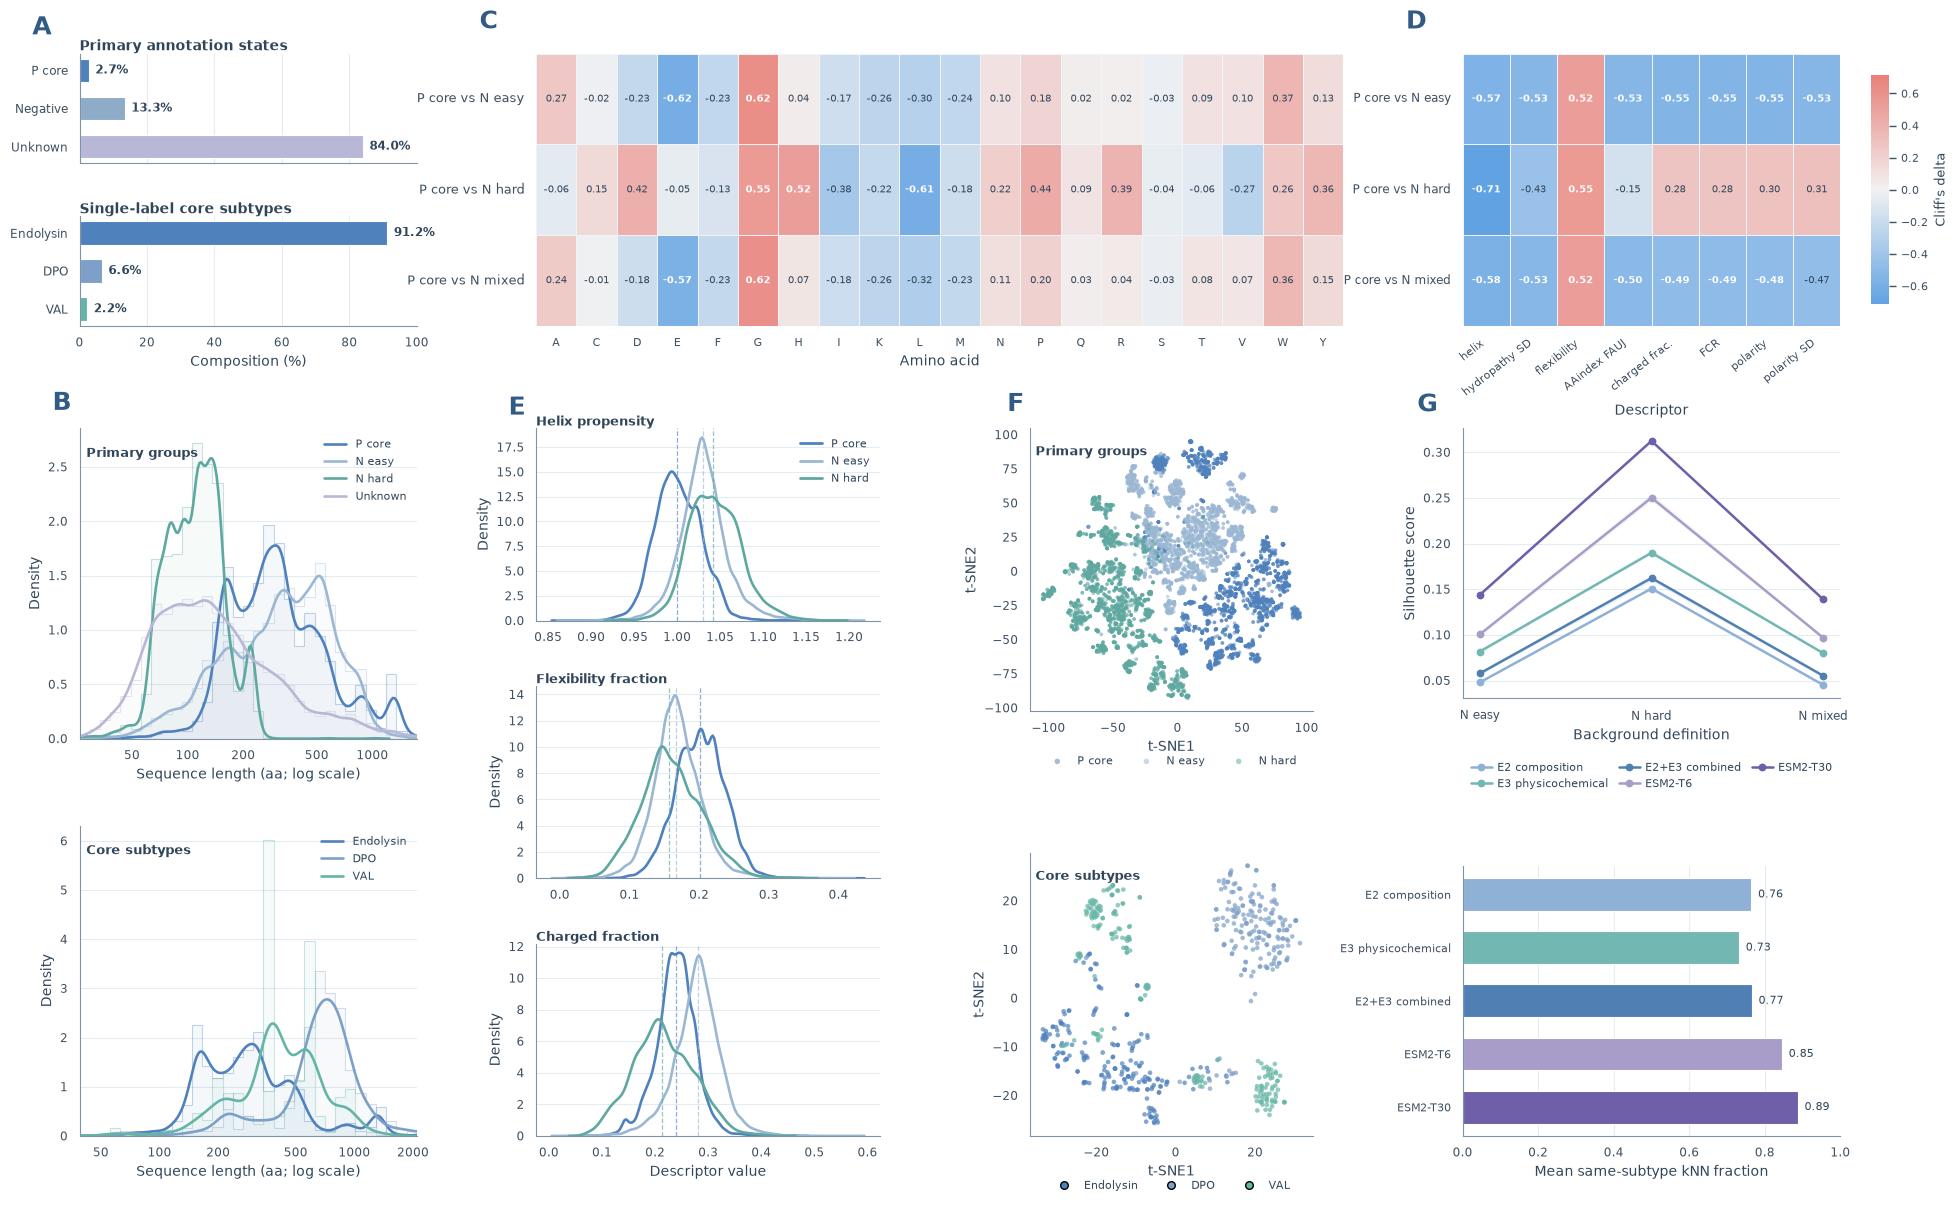

In [5]:
# ------------------------------------------------------------------
# Build final 3 × 4 manuscript figure
# ------------------------------------------------------------------
fig = plt.figure(figsize=(19.5, 12.0), facecolor="white")
outer = GridSpec(
    3, 4,
    figure=fig,
    width_ratios=[1.00, 1.02, 1.02, 1.12],
    height_ratios=[0.90, 1.00, 1.00],
    wspace=0.34,
    hspace=0.35,
)

# ================================================================
# A — percentage horizontal bars
# ================================================================
gsA = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[0, 0], hspace=0.48)
axA1 = fig.add_subplot(gsA[0, 0])
axA2 = fig.add_subplot(gsA[1, 0])
add_panel_letter(axA1, "A", x=-0.14, y=1.12)
plot_percentage_bars(axA1, primary_comp, ["P core", "Negative", "Unknown"], "Primary annotation states")
plot_percentage_bars(axA2, subtype_comp, ["Endolysin", "DPO", "VAL"], "Single-label core subtypes")
axA1.set_xlabel("")
axA1.tick_params(axis="x", labelbottom=False)

# ================================================================
# C — all amino acids; spans two columns
# ================================================================
axC = fig.add_subplot(outer[0, 1:3])
add_panel_letter(axC, "C", x=-0.07, y=1.07)
sns.heatmap(
    aac_matrix,
    ax=axC,
    cmap=DIVERGING_CMAP,
    center=0,
    vmin=-HEATMAP_LIM,
    vmax=HEATMAP_LIM,
    linewidths=0.55,
    linecolor="#F0F4F8",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7.4},
    cbar=False,
)
axC.set_xlabel("Amino acid")
axC.set_ylabel("")
axC.tick_params(axis="x", rotation=0, labelsize=8.2)
axC.tick_params(axis="y", rotation=0, labelsize=9.0)
recolor_heatmap_annotations(axC)

# ================================================================
# D — top physicochemical descriptors; shares C's color scale
# ================================================================
axD = fig.add_subplot(outer[0, 3])
add_panel_letter(axD, "D", x=-0.15, y=1.07)
cbar_ax = axD.inset_axes([1.08, 0.08, 0.050, 0.84])
sns.heatmap(
    desc_matrix,
    ax=axD,
    cmap=DIVERGING_CMAP,
    center=0,
    vmin=-HEATMAP_LIM,
    vmax=HEATMAP_LIM,
    linewidths=0.55,
    linecolor="#F0F4F8",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7.2},
    cbar=True,
    cbar_ax=cbar_ax,
    cbar_kws={"label": "Cliff's delta"},
)
axD.set_xlabel("Descriptor")
axD.set_ylabel("")
axD.tick_params(axis="x", rotation=38, labelsize=7.7)
for label in axD.get_xticklabels():
    label.set_ha("right")
axD.tick_params(axis="y", rotation=0, labelsize=8.4)
cbar_ax.tick_params(labelsize=8.0)
cbar_ax.yaxis.label.set_size(9.0)
recolor_heatmap_annotations(axD)

# ================================================================
# B — length distributions; two equal stacked plots
# ================================================================
gsB = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[1:3, 0], hspace=0.28)
axB1 = fig.add_subplot(gsB[0, 0])
axB2 = fig.add_subplot(gsB[1, 0])
add_panel_letter(axB1, "B")
plot_length_distribution(
    axB1,
    length_global,
    ["P_core", "N_easy", "N_hard", "Unknown"],
    LENGTH_GLOBAL_PALETTE,
)
plot_length_distribution(
    axB2,
    length_subtypes,
    ["Endolysin", "DPO", "VAL"],
    LENGTH_SUBTYPE_PALETTE,
)
axB1.text(0.02, 0.94, "Primary groups", transform=axB1.transAxes, fontsize=9.5, fontweight="bold", va="top")
axB2.text(0.02, 0.94, "Core subtypes", transform=axB2.transAxes, fontsize=9.5, fontweight="bold", va="top")

# ================================================================
# E — selected physicochemical distributions
# ================================================================
gsE = GridSpecFromSubplotSpec(3, 1, subplot_spec=outer[1:3, 1], hspace=0.34)
axesE = [fig.add_subplot(gsE[i, 0]) for i in range(3)]
add_panel_letter(axesE[0], "E")
for ax, feature in zip(axesE, selected_properties):
    label = PROPERTY_LABELS.get(feature, short_descriptor(feature))
    if property_mode == "raw":
        plot_property_raw(ax, property_raw, feature, label)
    else:
        plot_property_summary(ax, property_summary, feature, label)

if property_mode == "raw":
    handles = [Line2D([0], [0], color=COLORS[g], lw=2, label=DISPLAY_NAMES[g]) for g in ["P_core", "N_easy", "N_hard"]]
    axesE[0].legend(handles=handles, frameon=False, fontsize=8.0, loc="upper right")
    axesE[-1].set_xlabel("Descriptor value")

# ================================================================
# F — ESM2-T30 t-SNE only; same representation and same plot size
# ================================================================
gsF = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[1:3, 2], hspace=0.50)
axF1 = fig.add_subplot(gsF[0, 0])
axF2 = fig.add_subplot(gsF[1, 0])
add_panel_letter(axF1, "F")

scatter_classes(
    axF1,
    e5_global,
    "TSNE1",
    "TSNE2",
    "sequence_state",
    ["P_core", "N_easy", "N_hard"],
    GLOBAL_PALETTE,
    s=7,
    alpha=0.52,
)
axF1.set_xlabel("t-SNE1")
axF1.set_ylabel("t-SNE2")
axF1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.0, markerscale=1.5, ncol=3)
axF1.text(0.02, 0.94, "Primary groups", transform=axF1.transAxes, fontsize=9.5, fontweight="bold", va="top")

scatter_classes(
    axF2,
    e5_subtypes,
    "TSNE1",
    "TSNE2",
    "subtype_label",
    ["endolysin", "depolymerase", "virion_associated_lytic_enzyme"],
    SUBTYPE_PALETTE,
    s=11,
    alpha=0.70,
)
axF2.set_xlabel("t-SNE1")
axF2.set_ylabel("t-SNE2")
axF2.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["Endolysin"], markersize=5.5, label="Endolysin"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["DPO"], markersize=5.5, label="DPO"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["VAL"], markersize=5.5, label="VAL"),
    ],
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    fontsize=8.0,
    ncol=3,
)
axF2.text(0.02, 0.94, "Core subtypes", transform=axF2.transAxes, fontsize=9.5, fontweight="bold", va="top")

# Keep both scatter plots identical in physical shape.
for ax in [axF1, axF2]:
    ax.set_box_aspect(1.0)

# ================================================================
# G — robustness curves + complementary summary bar plot
# ================================================================
gsG = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[1:3, 3], hspace=0.62)
axG1 = fig.add_subplot(gsG[0, 0])
axG2 = fig.add_subplot(gsG[1, 0])
add_panel_letter(axG1, "G", x=-0.12, y=1.04)

background_order = ["N_easy", "N_hard", "N_mixed"]
x = np.arange(len(background_order))
for rep in rep_order:
    sub = (
        bg_sil.loc[bg_sil["display_name"].eq(rep)]
        .set_index("background")
        .reindex(background_order)
    )
    mean = sub["mean"].to_numpy(dtype=float)
    q25 = sub["q25"].to_numpy(dtype=float)
    q75 = sub["q75"].to_numpy(dtype=float)
    axG1.fill_between(x, q25, q75, color=COLORS[rep], alpha=0.10, linewidth=0)
    axG1.plot(x, mean, marker="o", markersize=4.6, linewidth=1.8, color=COLORS[rep], label=rep)

axG1.set_xticks(x)
axG1.set_xticklabels([DISPLAY_NAMES.get(x, x) for x in background_order])
axG1.set_ylabel("Silhouette score")
axG1.set_xlabel("Background definition")
axG1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.20), fontsize=7.6, ncol=3, labelspacing=0.45, columnspacing=1.0, handletextpad=0.5)
style_axis(axG1, grid=True)

bar_y = np.arange(len(rep_order))[::-1]
bar_vals = subtype_knn_rep["value"].to_numpy(dtype=float)
bar_colors = [COLORS[r] for r in rep_order]
axG2.barh(bar_y, bar_vals, color=bar_colors, height=0.62, edgecolor="white", linewidth=0.8)
axG2.set_yticks(bar_y)
axG2.set_yticklabels(rep_order, fontsize=8.0)
axG2.set_xlim(0, 1.0)
axG2.set_xlabel("Mean same-subtype kNN fraction")
for yy, val in zip(bar_y, bar_vals):
    axG2.text(min(val + 0.018, 0.985), yy, f"{val:.2f}", va="center", ha="left" if val < 0.94 else "right", fontsize=8.0)
style_axis(axG2, grid=True, axis="x")

# ------------------------------------------------------------------
# Final layout and export
# ------------------------------------------------------------------
fig.subplots_adjust(left=0.055, right=0.958, top=0.972, bottom=0.070)

PNG_PATH = OUTPUT_DIR / "phagelysdata_eda_panel_v6.png"
PDF_PATH = OUTPUT_DIR / "phagelysdata_eda_panel_v6.pdf"
fig.savefig(PNG_PATH, dpi=350, bbox_inches="tight")
fig.savefig(PDF_PATH, bbox_inches="tight")

print("Saved:", PNG_PATH)
print("Saved:", PDF_PATH)
plt.show()
